# Portion 7A — Confirmatory GPU runs in ≤ 3 h: pretraining seeds, a foundation-initialised encoder (B6), foundation baselines, temporal mechanism
**Why this portion.** Portions 3–6 on your 5 movies gave a clear but single-seed picture: self-supervised encoders read coverage 2–3× better
than a random encoder with ~10 % of the labels, but B3/B4/B5 are close to each other (one pretraining run per fold), there is no ImageNet /
foundation-model baseline yet (plan baseline B1), and forecasting lost to persistence because of the non-assembling 2 nM movie (Portion 7B).

| Section | Plan item | What it does |
|---|---|---|
| 4 Foundation baselines | E2 baseline B1 | frozen **ImageNet ViT-S/16** and **DINOv2 ViT-S/14** features of every frame |
| 5–6 Training (one queue, ≤ 3 h) | E7 seeds + new model | **B6** = DINOv2-initialised temporal MAE + InfoNCE, anchored to its foundation weights (L2-SP) — the candidate to beat every earlier encoder; then 2 extra seeds of B2–B5 on the 5 LOCO folds with the **Portion 3 recipe** |
| 7 Embeddings | – | per-frame embeddings of every new encoder (+ random-init B0 seeds) |
| 8–10 Figures, temporal mechanism | E8 "does time matter?" | seed reproducibility; frame-occlusion importance, order sensitivity, motion test for B3/B4/B5/B6 |

**Speed design (≈ 2–3× faster than Portion 3 per run):** clip sampling, cropping and augmentation run entirely on the GPU with no host
synchronisation, losses are logged without per-step syncs, checkpoints go to the fast local disk (only the final fp16 encoder is written to Drive),
and 3 trainings share the A100. A **time-budget scheduler** starts a run only if it will finish before the deadline, in priority order
(B6 → seed 1 → seed 2), so the notebook ends inside `TIME_BUDGET_H` even if the GPU is slower than expected; anything left over resumes next time.
**Drive space:** ≈ 2 GB (45 fp16 encoders + embeddings). **Then run Portion 7B** (CPU is fine).

In [1]:
# ---- 0. Mount Google Drive -------------------------------------------------
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running in Colab - using local paths.')

Mounted at /content/drive


In [2]:
# ---- 1. Imports, device, journal style ---------------------------------------------------------------------
import os, sys, json, time, glob, subprocess, tempfile, importlib, warnings, logging, zlib, hashlib
from datetime import datetime
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker
from matplotlib import font_manager
from IPython.display import display
warnings.filterwarnings('ignore'); logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40)
T_NOTEBOOK = time.time()                                       # the time budget is counted from here
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0), f'| {torch.cuda.get_device_properties(0).total_memory / 1e9:.0f} GB')
else:
    print('No GPU: fine for a smoke test only. Use Runtime > Change runtime type > A100 GPU for the real run.')
print('torch', torch.__version__, '| numpy', np.__version__, '| pandas', pd.__version__, '| python', sys.version.split()[0])

MM = 1 / 25.4; W1, W15, W2 = 89 * MM, 120 * MM, 183 * MM
_avail = {f.name for f in font_manager.fontManager.ttflist}
FONT = next((f for f in ['Arial', 'Helvetica', 'Liberation Sans', 'DejaVu Sans'] if f in _avail), 'DejaVu Sans')
plt.rcParams.update({'font.family': 'sans-serif', 'font.sans-serif': [FONT], 'font.size': 7, 'axes.titlesize': 7.5,
                     'axes.labelsize': 7, 'xtick.labelsize': 6.5, 'ytick.labelsize': 6.5, 'legend.fontsize': 6.3,
                     'axes.linewidth': 0.6, 'xtick.major.width': 0.6, 'ytick.major.width': 0.6, 'xtick.major.size': 2.5,
                     'ytick.major.size': 2.5, 'lines.linewidth': 1.1, 'lines.markersize': 3.5, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': False, 'legend.frameon': False, 'figure.dpi': 150,
                     'savefig.dpi': 600, 'pdf.fonttype': 42, 'ps.fonttype': 42, 'axes.titlelocation': 'left'})
def panel(ax, s, x=-0.16, y=1.04):
    ax.text(x, y, s, transform=ax.transAxes, fontsize=9, fontweight='bold', va='bottom', ha='left')

GPU: NVIDIA A100-SXM4-40GB | 42 GB
torch 2.11.0+cu130 | numpy 2.1.3 | pandas 2.2.3 | python 3.13.15


In [3]:
# ---- 2. Configuration ------------------------------------------------------------------------------------------
DATA_DIR = '/content/drive/MyDrive/Koushik-experiment/'
DATA_DIR = os.environ.get('HSAFM_DATA_DIR', DATA_DIR)          # (local-testing override; ignore in Colab)
P1_DIR, P2_DIR, P3_DIR = [os.path.join(DATA_DIR, f'portion{i}_outputs') for i in (1, 2, 3)]
OUT_DIR = os.path.join(DATA_DIR, 'portion7_outputs')
FIG, RUNS7, EMB7, EMBF = [os.path.join(OUT_DIR, d) for d in ('figures', 'runs_seeds', 'embeddings_seeds', 'embeddings_foundation')]
LOCAL = '/content/p7_local' if os.path.isdir('/content') else os.path.join(tempfile.gettempdir(), 'p7_local')   # fast disk: checkpoints
for d in [OUT_DIR, FIG, RUNS7, EMB7, EMBF, LOCAL]:
    os.makedirs(d, exist_ok=True)
need = [os.path.join(P1_DIR, 'splits.json'), os.path.join(P2_DIR, 'targets_per_frame.csv'), os.path.join(P3_DIR, 'run_config_portion3.json'),
        os.path.join(P3_DIR, 'dataset_index.csv'), os.path.join(P3_DIR, 'dataset_5nm_f16.npy')]
missing = [f for f in need if not os.path.exists(f)]
assert not missing, 'Run Portions 1-3 first. Missing:\n' + '\n'.join(missing)
p3cfg = json.load(open(os.path.join(P3_DIR, 'run_config_portion3.json'))); QUICK_P3 = bool(p3cfg.get('QUICK', False))
assert DEVICE.type == 'cuda' or QUICK_P3, ('Portion 7A trains full-size ViT encoders: switch to a GPU runtime '
                                           '(Runtime > Change runtime type > A100 GPU) and run all cells again.')

TIME_BUDGET_H = 2.75                       # whole notebook (from the imports cell); training stops starting new runs in time to finish
RESERVE_MIN = 20                           # minutes kept for embeddings, temporal tests and figures after training
SEED_LIST = [1, 2]                         # extra pretraining seeds (seed 0 = your Portion 3 runs, reused unchanged)
SEED_VARIANTS = ['B4', 'B5', 'B3', 'B2']   # priority order inside each seed (time-order claim first)
TRAIN_B6 = True                            # B6 = foundation-initialised temporal MAE + InfoNCE (trained first: highest value)
B6_INIT = 'B1-DINO'                        # 'B1-DINO' (DINOv2 ViT-S/14) or 'B1-IN' (ImageNet ViT-S/16)
B6_ENC_LR_MULT = 0.25                      # pretrained encoder learns 4x slower than the new decoder/projector (standard for adaptation)
B6_ANCHOR = 2.0                            # L2-SP: encoder decays towards its FOUNDATION weights (not towards 0); pull time constant ~ run length
N_WORKERS = 'auto'                         # trainings side by side on ONE GPU: auto = 4 on 80 GB, 3 on 40 GB, 2 on 16-24 GB
FOUNDATION = {'B1-IN': 'vit_small_patch16_224.augreg_in21k_ft_in1k',     # ImageNet-21k -> 1k ViT-S/16 (plan baseline B1)
              'B1-DINO': 'vit_small_patch14_dinov2.lvd142m'}             # DINOv2 ViT-S/14 (self-supervised foundation model)
FOUND_SIZE = 224
N_TEMPORAL = 96                            # held-out clips per fold for the temporal tests
SEED = 0
if os.environ.get('HSAFM_WORKERS'): N_WORKERS = int(os.environ['HSAFM_WORKERS'])   # (local-testing overrides)
if os.environ.get('HSAFM_BUDGET_H'): TIME_BUDGET_H = float(os.environ['HSAFM_BUDGET_H'])
if QUICK_P3:
    N_TEMPORAL = 16
splits = json.load(open(os.path.join(P1_DIR, 'splits.json')))['splits']
LOCO = [s for s in splits if s.startswith('LOCO_')]
VCOL = {'B0': '#9a9a9a', 'B1-IN': '#7d5a3c', 'B1-DINO': '#b08bd6', 'B2': '#1baf7a', 'B3': '#eb6834', 'B4': '#2a78d6', 'B5': '#eda100', 'B6': '#c2307a'}
VNAME = {'B0': 'B0 random init', 'B1-IN': 'B1 ImageNet ViT-S', 'B1-DINO': 'B1 DINOv2 ViT-S', 'B2': 'B2 frame MAE', 'B3': 'B3 temporal MAE',
         'B4': 'B4 temporal MAE + InfoNCE', 'B5': 'B5 shuffled time', 'B6': 'B6 = B4 from DINOv2 weights'}
missing_runs = [f'{s}__{v}' for s in LOCO for v in SEED_VARIANTS if not os.path.exists(os.path.join(P3_DIR, 'runs', f'{s}__{v}', 'final.pt'))]
assert not missing_runs, f'Portion 3 encoders missing (seed 0): {missing_runs}'
DEADLINE = T_NOTEBOOK + TIME_BUDGET_H * 3600 - RESERVE_MIN * 60
print(f'Portion-3 QUICK={QUICK_P3} | LOCO folds {LOCO} | seeds {SEED_LIST} x {SEED_VARIANTS} | B6 from {B6_INIT if TRAIN_B6 else "-"}')
print(f'time budget {TIME_BUDGET_H:.2f} h -> no new training run starts after {datetime.fromtimestamp(DEADLINE):%H:%M:%S} unless it fits')
def save(fig, name):
    for ext in ('pdf', 'png'):
        fig.savefig(os.path.join(FIG, f'{name}.{ext}'), bbox_inches='tight')
    plt.show()

Portion-3 QUICK=False | LOCO folds ['LOCO_2nM', 'LOCO_4nM', 'LOCO_6nM', 'LOCO_8nM', 'LOCO_10nM'] | seeds [1, 2] x ['B4', 'B5', 'B3', 'B2'] | B6 from B1-DINO
time budget 2.75 h -> no new training run starts after 18:13:55 unless it fits


In [4]:
%%writefile p7_core.py
"""Portion 7 core: the Portion 3 model and training recipe as an importable module, with a synchronisation-free GPU data path.
Imported by the notebook (embeddings, temporal tests) and run as background training workers:  python p7_core.py --data ... --jobs ..."""
import os, sys, json, time, math, zlib, random, argparse, traceback
from datetime import datetime
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F


class _Ctx:
    pass


C = _Ctx()
ENC_KEYS = ('patch_embed', 'blocks', 'norm', 'pos')            # encoder state saved for every new run (fp16)


def setup(data_dir, device=None, threads=0):
    """Portion 3 configuration + dataset cache on the device (same files and rules as Portion 3)."""
    p3_dir = os.path.join(data_dir, 'portion3_outputs')
    p3 = json.load(open(os.path.join(p3_dir, 'run_config_portion3.json')))
    cfg = p3['config']
    C.data_dir, C.p1_dir, C.p3_dir = data_dir, os.path.join(data_dir, 'portion1_outputs'), p3_dir
    C.QUICK = bool(p3.get('QUICK', False))
    for k in ['CROP', 'PATCH', 'TUBELET', 'ENC_DIM', 'ENC_DEPTH', 'ENC_HEADS', 'DEC_DIM', 'DEC_DEPTH', 'DEC_HEADS', 'STEPS',
              'BATCH_PAIRS', 'BATCH_FRAMES', 'WARMUP', 'CKPT_EVERY', 'LOG_EVERY', 'T_FRAMES', 'MAX_OFFSET', 'EMB_BATCH', 'SEED']:
        setattr(C, k, int(cfg[k]))
    for k in ['LR', 'WD', 'MASK_TUBE', 'MASK_FRAME', 'LAMBDA_NCE', 'TAU', 'TARGET_DT', 'H_CLIP', 'H_SCALE']:
        setattr(C, k, float(cfg[k]))
    if threads:
        torch.set_num_threads(int(threads))
    C.DEVICE = device if device is not None else torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    C.USE_AMP = C.DEVICE.type == 'cuda'
    C.AMP_DTYPE = torch.bfloat16 if (C.USE_AMP and torch.cuda.is_bf16_supported()) else torch.float16
    if C.DEVICE.type == 'cuda':
        torch.backends.cuda.matmul.allow_tf32 = True
        torch.backends.cudnn.allow_tf32 = True
        torch.backends.cudnn.benchmark = True
    C.splits = json.load(open(os.path.join(C.p1_dir, 'splits.json')))['splits']
    kept = pd.read_csv(os.path.join(p3_dir, 'dataset_index.csv'))      # = Portion 3 row order of the cache
    kept['pos'] = kept.groupby('session').cumcount()
    dt_sess = kept.groupby('session').t_rel_s.apply(lambda s: float(np.median(np.diff(s.values))) if len(s) > 1 else C.TARGET_DT)
    kept['stride'] = kept.session.map(lambda s: max(1, int(round(C.TARGET_DT / max(dt_sess[s], 1e-3)))))
    C.kept = kept
    C.SESS = {}
    for s, g in kept.groupby('session', sort=False):
        C.SESS[s] = dict(gidx=g.index.values, conc=g.conc.iloc[0], stride=int(g.stride.iloc[0]))
    X_np = np.load(os.path.join(p3_dir, 'dataset_5nm_f16.npy'), mmap_mode='r')
    assert len(X_np) == len(kept), 'dataset cache and dataset_index.csv differ - re-run Portion 3'
    C.H0, C.W0 = X_np.shape[1:]
    C.X_dev = torch.from_numpy(np.array(X_np)).to(C.DEVICE)                # writable copy (0.3 GB)
    return C


def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)


def to_input(x):
    """nm -> network input with fixed physical scaling (mica -1, origami ~+1)."""
    return (x.float().clamp(-1.0, 4.0) - C.H_CLIP) / C.H_SCALE


def session_table(concs, T, max_off):
    rows = []
    for s, v in C.SESS.items():
        if v['conc'] not in concs:
            continue
        n_start = len(v['gidx']) - (T - 1 + max_off) * v['stride']
        if n_start > 0:
            rows.append((s, n_start))
    return rows


class GPUClipSampler:
    """Portion 3 clip sampler, drawn entirely on the device (no host round-trip per step). Same distribution:
    session ~ number of valid starts, start ~ uniform, positive-pair offset ~ uniform{1..MAX_OFFSET} clip steps."""
    def __init__(self, concs, T, max_off, gen):
        self.T, self.max_off, self.g = T, max_off, gen
        rows = session_table(concs, T, max_off)
        if not rows:
            self.max_off = 0; rows = session_table(concs, T, 0)
        assert rows, f'no session long enough for {T}-frame clips in {concs}'
        sess = [r[0] for r in rows]; L = max(len(C.SESS[s]['gidx']) for s in sess)
        lut = np.zeros((len(sess), L), np.int64)
        for i, s in enumerate(sess):
            gi = C.SESS[s]['gidx']; lut[i, :len(gi)] = gi
        dev = C.DEVICE
        self.lut = torch.as_tensor(lut, device=dev)
        w = np.array([r[1] for r in rows], float); self.p = torch.as_tensor(w / w.sum(), device=dev, dtype=torch.float32)
        self.nstart = torch.as_tensor([r[1] for r in rows], device=dev, dtype=torch.float32)
        self.stride = torch.as_tensor([C.SESS[s]['stride'] for s in sess], device=dev)
        self.ar = torch.arange(T, device=dev)

    def sample_idx(self, B):
        dev = C.DEVICE
        si = torch.multinomial(self.p, B, replacement=True, generator=self.g)
        st = (torch.rand(B, device=dev, generator=self.g) * self.nstart[si]).long().clamp(max=(self.nstart[si] - 1).long())
        s = self.stride[si]
        pa = st[:, None] + s[:, None] * self.ar[None]
        if self.max_off > 0:
            d = torch.randint(1, self.max_off + 1, (B,), device=dev, generator=self.g); pb = pa + (d * s)[:, None]
        else:
            pb = pa
        return self.lut[si[:, None], pa], self.lut[si[:, None], pb]


def crop_aug(idx_list, crop, train=True, gen=None, shuffle_time=False):
    """idx_list: list of (B,T) index tensors sharing crop & augmentation -> list of (B,1,T,crop,crop) inputs.
    Same augmentations as Portion 3 (random crop, 3 flips, gain 0.9-1.1, B5: one time permutation per pair), drawn on the device."""
    B, T = idx_list[0].shape; dev = C.DEVICE
    if train:
        oy = (torch.rand(B, device=dev, generator=gen) * (C.H0 - crop + 1)).long().clamp(max=C.H0 - crop)
        ox = (torch.rand(B, device=dev, generator=gen) * (C.W0 - crop + 1)).long().clamp(max=C.W0 - crop)
        flips = torch.rand(B, 3, device=dev, generator=gen) < 0.5
        gain = 0.9 + 0.2 * torch.rand(B, device=dev, generator=gen)
        perm = torch.rand(B, T, device=dev, generator=gen).argsort(1) if shuffle_time else None
    else:
        oy = torch.full((B,), (C.H0 - crop) // 2, device=dev); ox = torch.full((B,), (C.W0 - crop) // 2, device=dev)
    ar = torch.arange(crop, device=dev)
    rows = (oy[:, None] + ar)[:, None, :, None]; cols = (ox[:, None] + ar)[:, None, None, :]
    out = []
    for idx in idx_list:
        if train and shuffle_time:
            idx = torch.gather(idx, 1, perm)
        x = to_input(C.X_dev[idx[:, :, None, None], rows, cols])
        if train:
            x = torch.where(flips[:, 0, None, None, None], x.flip(-1), x)
            x = torch.where(flips[:, 1, None, None, None], x.flip(-2), x)
            x = torch.where(flips[:, 2, None, None, None], x.transpose(-1, -2), x)
            x = x * gain[:, None, None, None]
        out.append(x[:, None])
    return out


# ---- model: verbatim Portion 3 code (dimensions passed explicitly instead of module defaults) ----
def sincos_1d(n, d):
    pos = np.arange(n, dtype=np.float64)[:, None]
    omega = 1.0 / 10000 ** (np.arange(d // 2, dtype=np.float64) / (d // 2))
    a = pos * omega[None]
    return np.concatenate([np.sin(a), np.cos(a)], axis=1)


def sincos_3d(t, h, w, dim):
    dt_ = 2 * (dim // 6); dh = 2 * (dim // 6); dw = dim - dt_ - dh
    et, eh, ew = sincos_1d(t, dt_), sincos_1d(h, dh), sincos_1d(w, dw if dw % 2 == 0 else dw - 1)
    if dw % 2: ew = np.concatenate([ew, np.zeros((w, 1))], 1)
    e = np.concatenate([np.repeat(et, h * w, 0), np.tile(np.repeat(eh, w, 0), (t, 1)), np.tile(ew, (t * h, 1))], 1)
    return torch.tensor(e, dtype=torch.float32)


class Block(nn.Module):
    def __init__(self, dim, heads, mlp=4.0):
        super().__init__()
        self.n1, self.n2 = nn.LayerNorm(dim), nn.LayerNorm(dim)
        self.qkv, self.proj, self.h = nn.Linear(dim, dim * 3), nn.Linear(dim, dim), heads
        self.mlp = nn.Sequential(nn.Linear(dim, int(dim * mlp)), nn.GELU(), nn.Linear(int(dim * mlp), dim))

    def forward(self, x):
        B, N, Cc = x.shape
        q, k, v = self.qkv(self.n1(x)).reshape(B, N, 3, self.h, Cc // self.h).permute(2, 0, 3, 1, 4)
        a = F.scaled_dot_product_attention(q, k, v)
        x = x + self.proj(a.transpose(1, 2).reshape(B, N, Cc))
        return x + self.mlp(self.n2(x))


class VideoMAE(nn.Module):
    def __init__(self, T, tubelet, crop, patch, dim, depth, heads, ddim, ddepth, dheads, proj_dim=128):
        super().__init__()
        self.T, self.tt, self.p = T, tubelet, patch
        self.gt, self.gs = T // tubelet, crop // patch
        self.patch_embed = nn.Conv3d(1, dim, kernel_size=(tubelet, patch, patch), stride=(tubelet, patch, patch))
        self.register_buffer('pos', sincos_3d(self.gt, self.gs, self.gs, dim)[None], persistent=False)
        self.register_buffer('dpos', sincos_3d(self.gt, self.gs, self.gs, ddim)[None], persistent=False)
        self.blocks = nn.ModuleList([Block(dim, heads) for _ in range(depth)]); self.norm = nn.LayerNorm(dim)
        self.dec_embed = nn.Linear(dim, ddim); self.mask_token = nn.Parameter(torch.zeros(1, 1, ddim))
        self.dblocks = nn.ModuleList([Block(ddim, dheads) for _ in range(ddepth)]); self.dnorm = nn.LayerNorm(ddim)
        self.head = nn.Linear(ddim, tubelet * patch * patch)
        self.proj = nn.Sequential(nn.Linear(dim, dim), nn.GELU(), nn.Linear(dim, proj_dim))
        nn.init.normal_(self.mask_token, std=0.02); self.apply(self._init)

    @staticmethod
    def _init(m):
        if isinstance(m, nn.Linear):
            nn.init.xavier_uniform_(m.weight)
            if m.bias is not None: nn.init.zeros_(m.bias)
        elif isinstance(m, nn.LayerNorm):
            nn.init.ones_(m.weight); nn.init.zeros_(m.bias)

    def patchify(self, x):
        B = x.shape[0]; tt, p, gt, gs = self.tt, self.p, self.gt, self.gs
        x = x.reshape(B, gt, tt, gs, p, gs, p).permute(0, 1, 3, 5, 2, 4, 6)
        return x.reshape(B, gt * gs * gs, tt * p * p)

    def make_mask(self, B, ratio, tube, gen_t):
        S, N = self.gs * self.gs, self.gt * self.gs * self.gs
        if tube:
            keep_s = max(1, int(round(S * (1 - ratio))))
            noise = torch.rand(B, S, device=self.pos.device, generator=gen_t)
            ids_s = noise.argsort(1)[:, :keep_s]
            ids_keep = (ids_s[:, None, :] + S * torch.arange(self.gt, device=ids_s.device)[None, :, None]).reshape(B, -1)
        else:
            keep = max(1, int(round(N * (1 - ratio))))
            ids_keep = torch.rand(B, N, device=self.pos.device, generator=gen_t).argsort(1)[:, :keep]
        mask = torch.ones(B, N, device=ids_keep.device); mask.scatter_(1, ids_keep, 0.0)
        return ids_keep.sort(1).values, mask

    def encode(self, x, ids_keep=None):
        tok = self.patch_embed(x).flatten(2).transpose(1, 2) + self.pos
        if ids_keep is not None:
            tok = torch.gather(tok, 1, ids_keep[..., None].expand(-1, -1, tok.shape[-1]))
        for b in self.blocks:
            tok = b(tok)
        return self.norm(tok)

    def forward_mae(self, x, ratio, tube, gen_t):
        B = x.shape[0]
        ids_keep, mask = self.make_mask(B, ratio, tube, gen_t)
        lat = self.encode(x, ids_keep)
        d = self.dec_embed(lat); N = mask.shape[1]
        full = self.mask_token.expand(B, N, -1).clone().to(d.dtype)
        full.scatter_(1, ids_keep[..., None].expand(-1, -1, d.shape[-1]), d)
        full = full + self.dpos
        for b in self.dblocks:
            full = b(full)
        pred = self.head(self.dnorm(full))
        tgt = self.patchify(x)
        mu, var = tgt.mean(-1, keepdim=True), tgt.var(-1, keepdim=True)
        tgt_n = (tgt - mu) / (var + 1e-6).sqrt()
        loss = (((pred.float() - tgt_n) ** 2).mean(-1) * mask).sum() / mask.sum()
        return loss, lat, pred, mask, (mu, var)

    @torch.no_grad()
    def embed(self, x):
        """frozen representation: [mean over all tokens, mean over the most recent tubelet]."""
        tok = self.encode(x)
        S = self.gs * self.gs
        return torch.cat([tok.mean(1), tok[:, -S:].mean(1)], dim=1)


def info_nce(za, zb, tau):
    za, zb = F.normalize(za.float(), dim=-1), F.normalize(zb.float(), dim=-1)
    logits = za @ zb.t() / tau
    lab = torch.arange(za.shape[0], device=za.device)
    return 0.5 * (F.cross_entropy(logits, lab) + F.cross_entropy(logits.t(), lab))


B6_DIM, B6_DEPTH, B6_HEADS = 384, 12, 6                      # ViT-S, identical to both foundation models


def make_model(variant):
    if variant == 'B6':                                      # same clip model as B4, ViT-S encoder with a learnable position embedding
        m = VideoMAE(T=C.T_FRAMES, tubelet=C.TUBELET, crop=C.CROP, patch=C.PATCH, dim=B6_DIM, depth=B6_DEPTH, heads=B6_HEADS,
                     ddim=C.DEC_DIM, ddepth=C.DEC_DEPTH, dheads=C.DEC_HEADS)
        pos = m.pos.clone(); del m.pos; m.pos = nn.Parameter(pos)
        for blk in m.blocks:
            blk.n1.eps = blk.n2.eps = 1e-6                   # foundation models use LayerNorm eps 1e-6
        m.norm.eps = 1e-6
        return m
    T, tt = (1, 1) if variant == 'B2' else (C.T_FRAMES, C.TUBELET)
    return VideoMAE(T=T, tubelet=tt, crop=C.CROP, patch=C.PATCH, dim=C.ENC_DIM, depth=C.ENC_DEPTH, heads=C.ENC_HEADS,
                    ddim=C.DEC_DIM, ddepth=C.DEC_DEPTH, dheads=C.DEC_HEADS)


def foundation_to_b6(fm, mean, std):
    """Encoder weights of a timm ViT-S (ImageNet or DINOv2) -> B6 encoder state. Exact re-parameterisations only:
    RGB patch filter -> one height channel (with the fixed height->grey->RGB normalisation folded into weight and bias),
    14-px -> 16-px patch (FlexiViT pseudo-inverse resampling), inflated over the 2-frame tubelet, LayerScale folded into the
    output projections, learned 2-D position embedding resampled to the crop grid + scaled temporal sin-cos."""
    from timm.layers import resample_patch_embed, resample_abs_pos_embed
    sd = {}
    w = fm.patch_embed.proj.weight.detach().float(); b = fm.patch_embed.proj.bias.detach().float()
    if w.shape[-1] != C.PATCH:
        w = resample_patch_embed(w, [C.PATCH, C.PATCH])
    mean = torch.tensor(mean, dtype=torch.float32).view(1, 3, 1, 1); std = torch.tensor(std, dtype=torch.float32).view(1, 3, 1, 1)
    ws = w / std                                             # x_rgb = (g - mean) / std,  g = (u * H_SCALE + H_CLIP + 0.5) / 3
    w_u = (ws * C.H_SCALE / 3.0).sum(1, keepdim=True)        # (D,1,p,p) weight on the network input u
    b_u = b + (ws * ((C.H_CLIP + 0.5) / 3.0 - mean)).sum((1, 2, 3))
    sd['patch_embed.weight'] = (w_u[:, :, None] / C.TUBELET).repeat(1, 1, C.TUBELET, 1, 1)
    sd['patch_embed.bias'] = b_u
    gs = C.CROP // C.PATCH; gt = C.T_FRAMES // C.TUBELET
    npre = getattr(fm, 'num_prefix_tokens', 1); pe = fm.pos_embed.detach().float()
    old = int(round((pe.shape[1] - npre) ** 0.5))
    sp = resample_abs_pos_embed(pe, [gs, gs], old_size=[old, old], num_prefix_tokens=npre)[:, npre:]        # (1, gs*gs, D)
    te = torch.tensor(sincos_1d(gt, sp.shape[-1]), dtype=torch.float32)
    te = te / (te.std() + 1e-8) * sp.std()
    sd['pos'] = (sp.repeat(1, gt, 1) + te.repeat_interleave(gs * gs, 0)[None])
    for i, blk in enumerate(fm.blocks):
        g1 = blk.ls1.gamma.detach().float() if hasattr(blk.ls1, 'gamma') else None
        g2 = blk.ls2.gamma.detach().float() if hasattr(blk.ls2, 'gamma') else None
        pw, pb = blk.attn.proj.weight.detach().float(), blk.attn.proj.bias.detach().float()
        fw, fb = blk.mlp.fc2.weight.detach().float(), blk.mlp.fc2.bias.detach().float()
        if g1 is not None: pw, pb = pw * g1[:, None], pb * g1
        if g2 is not None: fw, fb = fw * g2[:, None], fb * g2
        sd.update({f'blocks.{i}.n1.weight': blk.norm1.weight, f'blocks.{i}.n1.bias': blk.norm1.bias,
                   f'blocks.{i}.qkv.weight': blk.attn.qkv.weight, f'blocks.{i}.qkv.bias': blk.attn.qkv.bias,
                   f'blocks.{i}.proj.weight': pw, f'blocks.{i}.proj.bias': pb,
                   f'blocks.{i}.n2.weight': blk.norm2.weight, f'blocks.{i}.n2.bias': blk.norm2.bias,
                   f'blocks.{i}.mlp.0.weight': blk.mlp.fc1.weight, f'blocks.{i}.mlp.0.bias': blk.mlp.fc1.bias,
                   f'blocks.{i}.mlp.2.weight': fw, f'blocks.{i}.mlp.2.bias': fb})
    sd['norm.weight'], sd['norm.bias'] = fm.norm.weight, fm.norm.bias
    return {k: v.detach().float().cpu().clone() for k, v in sd.items()}


def run_dir(runs_root, split, variant, seed):
    return os.path.join(runs_root, f'{split}__{variant}__s{seed}')


def run_status(runs_root, split, variant, seed, local_root=None):
    rd = run_dir(runs_root, split, variant, seed); mj = os.path.join(rd, 'meta.json')
    if not os.path.exists(os.path.join(rd, 'final_encoder.pt')) or not os.path.exists(mj):
        ck = os.path.join(local_root, f'{split}__{variant}__s{seed}.pt') if local_root else ''
        return 'partial' if ck and os.path.exists(ck) else 'new'
    meta = json.load(open(mj))
    ok = (sorted(meta.get('train_concs', [])) == sorted(C.splits[split]['train']) and meta.get('QUICK') == C.QUICK
          and meta.get('step') == C.STEPS and meta.get('seed') == seed)
    return 'done' if ok else 'stale'


def lr_at(step):
    if step < C.WARMUP:
        return C.LR * (step + 1) / C.WARMUP
    q = (step - C.WARMUP) / max(1, C.STEPS - C.WARMUP)
    return C.LR * 0.5 * (1 + math.cos(math.pi * min(1.0, q)))


def train_one(split, variant, seed, runs_root, local_root, b6_init=None, b6_lr_mult=0.25, b6_anchor=2.0):
    """Portion 3 recipe (same losses, masks, augmentation, optimiser, schedule, batch and steps); seed is a parameter.
    Optimised: device-side sampling, no per-step host sync, local checkpoints, fp16 encoder-only final weights."""
    rd = run_dir(runs_root, split, variant, seed); os.makedirs(rd, exist_ok=True)
    fin, mj = os.path.join(rd, 'final_encoder.pt'), os.path.join(rd, 'meta.json')
    ck = os.path.join(local_root, f'{split}__{variant}__s{seed}.pt')
    st_ = run_status(runs_root, split, variant, seed, local_root)
    if st_ == 'done':
        return 'done'
    if st_ == 'stale':
        for f in (fin, mj, ck):
            if os.path.exists(f): os.remove(f)
    train_concs = C.splits[split]['train']
    seed_all(seed)
    gen = torch.Generator(device=C.DEVICE).manual_seed(seed * 100003 + zlib.crc32((split + variant).encode()) % 100000)
    gen_t = torch.Generator(device=C.DEVICE).manual_seed(seed)
    model = make_model(variant)
    if variant == 'B6':
        assert b6_init and os.path.exists(b6_init), 'B6 needs the converted foundation weights (notebook section 4)'
        miss, unexp = model.load_state_dict(torch.load(b6_init, map_location='cpu'), strict=False)
        assert not unexp and all(k.split('.')[0] not in ENC_KEYS for k in miss), f'B6 init mismatch: {unexp[:3]} {miss[:3]}'
    model = model.to(C.DEVICE)
    enc = [p for n, p in model.named_parameters() if n.split('.')[0] in ENC_KEYS]
    rest = [p for n, p in model.named_parameters() if n.split('.')[0] not in ENC_KEYS]
    mult = b6_lr_mult if variant == 'B6' else 1.0
    anchor = b6_anchor if variant == 'B6' else 0.0
    enc0 = [p.detach().clone() for p in enc] if anchor > 0 else None      # L2-SP anchor = the foundation weights
    groups = [dict(params=enc, lr_mult=mult, weight_decay=0.0 if anchor > 0 else C.WD), dict(params=rest, lr_mult=1.0, weight_decay=C.WD)]
    try:
        opt = torch.optim.AdamW(groups, lr=C.LR, betas=(0.9, 0.95), weight_decay=C.WD, fused=C.DEVICE.type == 'cuda')
    except (TypeError, RuntimeError):
        opt = torch.optim.AdamW(groups, lr=C.LR, betas=(0.9, 0.95), weight_decay=C.WD)
    scaler = torch.amp.GradScaler('cuda', enabled=(C.USE_AMP and C.AMP_DTYPE == torch.float16))
    step, log = 0, []
    if os.path.exists(ck):
        st = torch.load(ck, map_location=C.DEVICE, weights_only=False)
        model.load_state_dict(st['model']); opt.load_state_dict(st['opt']); step = st['step']; log = st['log']
        gen.manual_seed(int(st.get('reseed', seed + step))); gen_t.manual_seed(int(st.get('reseed', seed + step)) + 1)
    sampler = GPUClipSampler(train_concs, 1, 0, gen) if variant == 'B2' else GPUClipSampler(train_concs, C.T_FRAMES, C.MAX_OFFSET, gen)
    model.train(); t0 = time.time()
    acc = torch.zeros(2, device=C.DEVICE); n_acc = 0
    zero = torch.zeros((), device=C.DEVICE)
    while step < C.STEPS:
        lr = lr_at(step)
        for g_ in opt.param_groups:
            g_['lr'] = lr * g_['lr_mult']
        with torch.autocast(device_type=C.DEVICE.type, dtype=C.AMP_DTYPE, enabled=C.USE_AMP):
            if variant == 'B2':
                ia, _ = sampler.sample_idx(C.BATCH_FRAMES)
                xa, = crop_aug([ia], C.CROP, True, gen)
                loss_rec, _, _, _, _ = model.forward_mae(xa, C.MASK_FRAME, False, gen_t)
                loss_nce = zero; loss = loss_rec
            else:
                ia, ib = sampler.sample_idx(C.BATCH_PAIRS)
                xa, xb = crop_aug([ia, ib], C.CROP, True, gen, shuffle_time=(variant == 'B5'))
                loss_rec, lat, _, _, _ = model.forward_mae(torch.cat([xa, xb]), C.MASK_TUBE, True, gen_t)
                if variant in ('B4', 'B5', 'B6'):
                    z = model.proj(lat.mean(1))
                    loss_nce = info_nce(z[:C.BATCH_PAIRS], z[C.BATCH_PAIRS:], C.TAU)
                    loss = loss_rec + C.LAMBDA_NCE * loss_nce
                else:
                    loss_nce = zero; loss = loss_rec
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update()
        if anchor > 0:                                       # decoupled pull towards the foundation weights: θ <- θ - lr·λ·(θ - θ0)
            with torch.no_grad():
                wgt = min(1.0, lr * mult * anchor)
                if hasattr(torch, '_foreach_lerp_'):
                    torch._foreach_lerp_(enc, enc0, wgt)
                else:
                    for p_, p0 in zip(enc, enc0): p_.lerp_(p0, wgt)
        acc += torch.stack([loss_rec.detach().float(), loss_nce.detach().float()]); n_acc += 1
        step += 1
        if step % C.LOG_EVERY == 0 or step == C.STEPS:                       # the only host sync: once per LOG_EVERY steps
            r, n = (acc / n_acc).tolist(); acc.zero_(); n_acc = 0
            log.append(dict(step=step, loss_rec=r, loss_nce=n, lr=lr_at(step), sec=time.time() - t0))
        if step % C.CKPT_EVERY == 0 and step < C.STEPS:
            torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), step=step, log=log, reseed=seed * 7919 + step), ck)
    enc_sd = {k: v.detach().to(torch.float16).cpu() for k, v in model.state_dict().items() if k.split('.')[0] in ENC_KEYS}
    tmp = fin + '.tmp'
    torch.save(dict(encoder=enc_sd, step=step, variant=variant, split=split, seed=seed, train_concs=train_concs,
                    config=dict(CROP=C.CROP, PATCH=C.PATCH, T=C.T_FRAMES, QUICK=C.QUICK, STEPS=C.STEPS)), tmp)
    os.replace(tmp, fin)
    pd.DataFrame(log).to_csv(os.path.join(rd, 'log.csv'), index=False)
    json.dump(dict(train_concs=list(train_concs), QUICK=C.QUICK, step=step, variant=variant, split=split, seed=seed,
                   b6_init=os.path.basename(b6_init) if variant == 'B6' else None, enc_lr_mult=mult, l2sp_anchor=anchor,
                   finished=datetime.now().isoformat(timespec='seconds')), open(mj, 'w'))
    if os.path.exists(ck):
        os.remove(ck)
    del model, opt
    if C.DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    return f'{time.time() - t0:.0f}'


def load_model(variant, split=None, seed=0, runs_root=None):
    """B0: seeded random init (seed 0 == Portion 3). B2-B5 seed 0: Portion 3 checkpoints. Everything else: fp16 encoders of runs_root."""
    if variant == 'B0':
        torch.manual_seed(seed); return make_model('B4').to(C.DEVICE).eval()
    m = make_model(variant)
    if seed == 0 and variant in ('B2', 'B3', 'B4', 'B5'):
        m.load_state_dict(torch.load(os.path.join(C.p3_dir, 'runs', f'{split}__{variant}', 'final.pt'), map_location='cpu', weights_only=False)['model'])
    else:
        st = torch.load(os.path.join(run_dir(runs_root, split, variant, seed), 'final_encoder.pt'), map_location='cpu', weights_only=False)
        miss, unexp = m.load_state_dict({k: v.float() for k, v in st['encoder'].items()}, strict=False)
        assert not unexp and all(k.split('.')[0] not in ENC_KEYS for k in miss), 'encoder checkpoint incomplete'
    return m.to(C.DEVICE).eval()


def causal_indices(T, rows=None):
    """(n,T) global indices of the clip ENDING at each frame (earlier frames repeated at a session start) - Portion 3 rule."""
    k = C.kept; rows = np.arange(len(k)) if rows is None else np.asarray(rows, int)
    start = (k.index.values - k.pos.values)[rows]
    off = np.clip(k.pos.values[rows][:, None] - k.stride.values[rows][:, None] * np.arange(T - 1, -1, -1)[None], 0, None)
    return start[:, None] + off


@torch.no_grad()
def extract(model, variant, rows=None, batch=None):
    idx = causal_indices(1 if variant == 'B2' else C.T_FRAMES, rows); batch = batch or C.EMB_BATCH; Z = []
    for i in range(0, len(idx), batch):
        x, = crop_aug([torch.as_tensor(idx[i:i + batch], device=C.DEVICE)], C.CROP, train=False)
        with torch.autocast(device_type=C.DEVICE.type, dtype=C.AMP_DTYPE, enabled=C.USE_AMP):
            Z.append(model.embed(x).float().cpu().numpy())
    return np.concatenate(Z).astype(np.float32)


@torch.no_grad()
def embed_inputs(model, x, batch=None):
    """embeddings of ready-made network inputs x (n,1,T,H,W), in batches."""
    batch = batch or C.EMB_BATCH; out = []
    for i in range(0, len(x), batch):
        with torch.autocast(device_type=C.DEVICE.type, dtype=C.AMP_DTYPE, enabled=C.USE_AMP):
            out.append(model.embed(x[i:i + batch]).float())
    return torch.cat(out)


def _worker(a):
    setup(a.data, threads=a.threads)
    jobs = json.load(open(a.jobs)); measured = []
    with open(a.log, 'a', buffering=1) as log:
        for j in jobs:
            key = f"{j['split']}__{j['variant']}__s{j['seed']}"
            unit = float(np.median(measured)) if measured else a.unit_sec              # seconds per cost unit, measured on this GPU
            if time.time() + 1.15 * unit * j['cost'] > a.deadline:
                log.write(f'SKIP {key} budget\n'); continue                          # would not finish inside the time budget
            try:
                fd = os.open(os.path.join(a.claims, key), os.O_CREAT | os.O_EXCL | os.O_WRONLY); os.close(fd)
            except FileExistsError:
                continue
            log.write(f'START {key} {time.time():.0f}\n'); t0 = time.time()
            try:
                res = train_one(j['split'], j['variant'], int(j['seed']), a.runs, a.local, a.b6_init, a.b6_lr_mult, a.b6_anchor)
            except Exception:
                log.write(f'ERROR {key}\n{traceback.format_exc()}\n')
                sys.exit(1)
            if res != 'done':
                measured.append((time.time() - t0) / j['cost'])
            log.write(f'DONE {key} {res}\n')
        log.write('EXIT\n')


if __name__ == '__main__':
    ap = argparse.ArgumentParser()
    for name in ('--data', '--jobs', '--claims', '--runs', '--local', '--log', '--b6_init'):
        ap.add_argument(name, required=True)
    ap.add_argument('--threads', type=int, default=0)
    ap.add_argument('--deadline', type=float, required=True)
    ap.add_argument('--unit_sec', type=float, default=600.0)
    ap.add_argument('--b6_lr_mult', type=float, default=0.25)
    ap.add_argument('--b6_anchor', type=float, default=2.0)
    _worker(ap.parse_args())

Writing p7_core.py


In [5]:
# ---- 3. Load the core module and verify it rebuilds the Portion 3 encoders exactly ----------------------------------------
CORE = os.path.abspath('p7_core.py')
sys.path.insert(0, os.path.dirname(CORE))
import p7_core as core
importlib.reload(core)
C = core.setup(DATA_DIR, DEVICE)
kept, CONCS = C.kept, sorted(C.kept.conc.unique(), key=lambda c: float(str(c).replace('nM', '')))
CCOL = {c: plt.get_cmap('Blues')(0.38 + 0.54 * i / max(1, len(CONCS) - 1)) for i, c in enumerate(CONCS)}
print(f'dataset {tuple(C.X_dev.shape)} on {C.DEVICE} | crop {C.CROP}px | ViT {C.ENC_DIM}x{C.ENC_DEPTH} | {C.STEPS} steps per run | QUICK={C.QUICK}')
s_chk = LOCO[len(LOCO) // 2]; rows_chk = np.linspace(0, len(kept) - 1, 8).astype(int); chk = []
for v in ['B0', 'B4', 'B2']:
    m = core.load_model(v, s_chk, 0)
    z_new = core.extract(m, v, rows_chk); z_old = np.load(os.path.join(P3_DIR, 'embeddings', s_chk, f'{v}.npz'))['Z'][rows_chk]
    r = float(np.corrcoef(z_new.ravel(), z_old.ravel())[0, 1]); chk.append(dict(split=s_chk, variant=v, correlation=r, ok=r > 0.995)); del m
CHK = pd.DataFrame(chk); display(CHK.round(5))
assert CHK.ok.all(), 'the core module does not reproduce the Portion 3 encoders - portion3_outputs may be incomplete'

dataset (4036, 200, 200) on cuda | crop 192px | ViT 384x12 | 6000 steps per run | QUICK=False


,split,variant,correlation,ok
0,LOCO_6nM,B0,1.0,True
1,LOCO_6nM,B4,1.0,True
2,LOCO_6nM,B2,1.0,True


In [6]:
# ---- 4. Foundation baselines B1 (frozen ImageNet ViT-S/16, DINOv2 ViT-S/14) + the B6 initial weights -----------------------------
try:
    import timm
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'timm', 'huggingface_hub', 'safetensors'], check=True)
    import timm
try:                                                   # quiet the 'unauthenticated requests' notice of the public download
    from huggingface_hub.utils import logging as hf_logging; hf_logging.set_verbosity_error()
except Exception:
    pass
print('timm', timm.__version__)

def load_foundation(name):
    """timm model with pretrained weights; falls back to a direct Hugging Face download if timm's own loader fails."""
    try:
        return timm.create_model(name, pretrained=True, num_classes=0, img_size=FOUND_SIZE), 'timm'
    except Exception as e:
        print(f'   timm loader failed for {name} ({type(e).__name__}: {str(e)[:120]}) -> direct download')
    from huggingface_hub import hf_hub_download
    from safetensors.torch import load_file
    m = timm.create_model(name, pretrained=False, num_classes=0, img_size=FOUND_SIZE)
    from timm.models.vision_transformer import checkpoint_filter_fn
    sd = checkpoint_filter_fn(load_file(hf_hub_download(f'timm/{name}', 'model.safetensors')), m)
    miss, unexp = m.load_state_dict(sd, strict=False)
    assert not [k for k in miss if not k.startswith('head')], f'missing weights: {miss[:5]}'
    return m, 'hf_hub'

def fresh(f, src=None):
    if not os.path.exists(f): return False
    try:
        z = np.load(f, allow_pickle=True)
        if len(z['frame_id']) != len(kept) or [str(x) for x in z['frame_id'][:3]] != [str(x) for x in kept.frame_id[:3]]: return False
    except Exception:
        return False
    return src is None or os.path.getmtime(f) >= os.path.getmtime(src)

@torch.no_grad()
def foundation_embed(m, batch):
    """single frame (Portion 3 centre crop) -> fixed physical grey scale (-0.5..2.5 nm -> 0..1) -> RGB -> model normalisation.
    embedding = [class token, mean of patch tokens] (2 x 384 = 768-d, same size as the Portion 3 embeddings)."""
    cfg = m.pretrained_cfg; mean = torch.tensor(cfg.get('mean', (0.5, 0.5, 0.5)), device=DEVICE).view(1, 3, 1, 1)
    std = torch.tensor(cfg.get('std', (0.5, 0.5, 0.5)), device=DEVICE).view(1, 3, 1, 1)
    idx = core.causal_indices(1); oy, ox = (C.H0 - C.CROP) // 2, (C.W0 - C.CROP) // 2; Z = []
    for i in range(0, len(idx), batch):
        h = C.X_dev[torch.as_tensor(idx[i:i + batch, 0], device=DEVICE)][:, oy:oy + C.CROP, ox:ox + C.CROP].float()
        g = ((h + 0.5) / 3.0).clamp(0, 1)[:, None]
        g = F.interpolate(g, size=(FOUND_SIZE, FOUND_SIZE), mode='bilinear', align_corners=False, antialias=True)
        x = (g.expand(-1, 3, -1, -1) - mean) / std
        with torch.autocast(device_type=DEVICE.type, dtype=C.AMP_DTYPE, enabled=C.USE_AMP):
            tok = m.forward_features(x).float()
        npre = getattr(m, 'num_prefix_tokens', 1)
        Z.append(torch.cat([tok[:, 0], tok[:, npre:].mean(1)], 1).cpu().numpy())
    return np.concatenate(Z).astype(np.float32)

B6_INIT_FILE = os.path.join(LOCAL, 'B6_init.pt'); FOUND_STATUS = []
for key, name in FOUNDATION.items():
    f = os.path.join(EMBF, f'{key}.npz')
    need_b6 = TRAIN_B6 and key == B6_INIT and not os.path.exists(B6_INIT_FILE)
    if fresh(f) and not need_b6:
        FOUND_STATUS.append(dict(baseline=key, model=name, status='cached')); continue
    t0 = time.time()
    try:
        m, src = load_foundation(name); m = m.to(DEVICE).eval()
        if not fresh(f):
            Z = foundation_embed(m, 128 if DEVICE.type == 'cuda' else 16)
            np.savez_compressed(f, Z=Z, frame_id=kept.frame_id.values.astype(str), variant=key, model=name, size=FOUND_SIZE,
                                train_concs=np.array([], dtype=str))
        if TRAIN_B6 and key == B6_INIT:
            cfg_ = m.pretrained_cfg
            torch.save(core.foundation_to_b6(m.cpu(), cfg_.get('mean', (0.5, 0.5, 0.5)), cfg_.get('std', (0.5, 0.5, 0.5))), B6_INIT_FILE)
        del m
        FOUND_STATUS.append(dict(baseline=key, model=name, status=f'ok ({src}, {time.time() - t0:.0f}s)'))
    except Exception as e:
        FOUND_STATUS.append(dict(baseline=key, model=name, status=f'SKIPPED: {type(e).__name__}: {str(e)[:150]}'))
if DEVICE.type == 'cuda': torch.cuda.empty_cache()
FOUND_STATUS = pd.DataFrame(FOUND_STATUS); display(FOUND_STATUS)
FOUND_OK = [k for k in FOUNDATION if fresh(os.path.join(EMBF, f'{k}.npz'))]
if TRAIN_B6 and not os.path.exists(B6_INIT_FILE):
    TRAIN_B6 = False; print('B6 skipped: its foundation weights could not be loaded.')
if TRAIN_B6:              # B6 at step 0 ('B6-init'): the foundation weights inside our clip pipeline -> reference for what training adds
    f0 = os.path.join(EMBF, 'B6-init.npz')
    if not fresh(f0, B6_INIT_FILE):
        m6 = core.make_model('B6'); m6.load_state_dict(torch.load(B6_INIT_FILE), strict=False); m6 = m6.to(DEVICE).eval()
        Z6 = core.extract(m6, 'B6'); del m6
        np.savez_compressed(f0, Z=Z6, frame_id=kept.frame_id.values.astype(str), variant='B6-init', model=FOUNDATION[B6_INIT],
                            train_concs=np.array([], dtype=str))
    z6 = np.load(f0)['Z']
    print(f'B6 at initialisation: embedding s.d. across frames {z6.std(0).mean():.3f} (a random encoder gives ~0) -> saved as B6-init')

timm 1.0.30


model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

,baseline,model,status
0,B1-IN,vit_small_patch16_224.augreg_in21k_ft_in1k,"ok (timm, 4s)"
1,B1-DINO,vit_small_patch14_dinov2.lvd142m,"ok (timm, 3s)"


B6 at initialisation: embedding s.d. across frames 0.698 (a random encoder gives ~0) -> saved as B6-init


In [7]:
# ---- 5. Training queue: B6 first, then seeds (priority order), sized to the time budget ---------------------------------------------
COST = {'B6': 1.0, 'B5': 1.06, 'B4': 1.0, 'B3': 0.99, 'B2': 0.62}            # relative run time on an A100 (Portion 3 logs)
planned = ([dict(split=s, variant='B6', seed=0) for s in LOCO] if TRAIN_B6 else []) + \
          [dict(split=s, variant=v, seed=sd) for sd in SEED_LIST for v in SEED_VARIANTS for s in LOCO]
for j in planned: j['cost'] = COST[j['variant']]
status = {(j['split'], j['variant'], j['seed']): core.run_status(RUNS7, j['split'], j['variant'], j['seed'], LOCAL) for j in planned}
jobs = [j for j in planned if status[(j['split'], j['variant'], j['seed'])] != 'done']
if DEVICE.type == 'cuda':
    gb = torch.cuda.get_device_properties(0).total_memory / 1e9
    nw_auto = 4 if gb >= 70 else (3 if gb >= 38 else (2 if gb >= 15 else 1))
else:
    nw_auto = 1
NW = nw_auto if N_WORKERS == 'auto' else max(1, int(N_WORKERS))
NW = max(1, min(NW, len(jobs))) if jobs else 0
UNIT0 = 393.0 * max(1, NW) / (2.0 if NW > 1 else 1.0) if DEVICE.type == 'cuda' else 60.0   # pessimistic first guess (s per B4-sized run)
units = sum(j['cost'] for j in jobs); left_h = (DEADLINE - time.time()) / 3600
print(f'{len(planned)} runs planned | {len(planned) - len(jobs)} already finished | {len(jobs)} queued ({units:.1f} B4-sized units) '
      f'| {NW} parallel worker(s) | {left_h:.2f} h of training time left in the budget')
display(pd.Series([v for v in status.values()]).value_counts().rename('runs'))

45 runs planned | 0 already finished | 45 queued (41.7 B4-sized units) | 3 parallel worker(s) | 2.40 h of training time left in the budget


,runs
new,45


In [8]:
# ---- 6. Train (parallel background workers, time-budgeted, resumable) ---------------------------------------------------------------
def tail(path, n=40):
    return ''.join(open(path).readlines()[-n:]) if os.path.exists(path) else ''

if jobs:
    claims = tempfile.mkdtemp(prefix='p7claims_'); jf = os.path.join(claims, '_jobs.json'); json.dump(jobs, open(jf, 'w'))
    logs = [os.path.join(claims, f'_worker{k}.log') for k in range(NW)]
    threads = max(1, (os.cpu_count() or 2) // NW)
    procs = [subprocess.Popen([sys.executable, '-u', CORE, '--data', DATA_DIR, '--jobs', jf, '--claims', claims, '--runs', RUNS7,
                               '--local', LOCAL, '--log', logs[k], '--threads', str(threads), '--deadline', str(DEADLINE),
                               '--unit_sec', str(UNIT0), '--b6_init', B6_INIT_FILE, '--b6_lr_mult', str(B6_ENC_LR_MULT),
                               '--b6_anchor', str(B6_ANCHOR)],
                              stdout=open(logs[k] + '.out', 'w'), stderr=subprocess.STDOUT, cwd=os.path.dirname(CORE)) for k in range(NW)]
    t_start, seen, poll = time.time(), set(), (2 if DEVICE.type != 'cuda' else 20)
    try:
        while True:
            time.sleep(poll)
            done = []
            for lg in logs:
                for line in (open(lg).read().splitlines() if os.path.exists(lg) else []):
                    if line.startswith('DONE '): done.append(line.split()[1:])
            for key, secs in done:
                if key not in seen:
                    seen.add(key); el = time.time() - t_start; left = len(jobs) - len(seen)
                    secs = float(secs) if secs.replace('.', '', 1).isdigit() else 0.0
                    print(f'[{len(seen)}/{len(jobs)}] {key:26s} {secs:5.0f} s | elapsed {el / 60:5.1f} min | at this pace the queue '
                          f'needs ~{el / len(seen) * left / 60:4.0f} min more | budget left {(DEADLINE - time.time()) / 60:4.0f} min', flush=True)
            bad = [k for k, p in enumerate(procs) if p.poll() not in (None, 0)]
            if bad:
                for p in procs:
                    if p.poll() is None: p.kill()
                raise RuntimeError(f'training worker {bad[0]} stopped with an error:\n' + tail(logs[bad[0]]) + tail(logs[bad[0]] + '.out'))
            if all(p.poll() == 0 for p in procs):
                break
    except KeyboardInterrupt:
        for p in procs:
            if p.poll() is None: p.kill()
        print('Interrupted - finished runs are kept; re-run the notebook to continue the queue.')
        raise
    print(f'training finished in {(time.time() - t_start) / 60:.1f} min with {NW} worker(s)')
DONE_RUNS = [j for j in planned if core.run_status(RUNS7, j['split'], j['variant'], j['seed'], LOCAL) == 'done']
DEFERRED = [f"{j['split']}__{j['variant']}__s{j['seed']}" for j in planned if j not in DONE_RUNS]
COMPLETE_SETS = sorted({(j['variant'], j['seed']) for j in planned if all(core.run_status(RUNS7, s, j['variant'], j['seed'], LOCAL) == 'done' for s in LOCO)})
print(f'{len(DONE_RUNS)}/{len(planned)} runs finished | complete 5-fold sets: {COMPLETE_SETS}')
if DEFERRED:
    print(f'{len(DEFERRED)} runs did not fit in this session (resume by re-running the notebook): {DEFERRED}')

[1/45] LOCO_6nM__B6__s0            1197 s | elapsed  20.3 min | at this pace the queue needs ~ 895 min more | budget left  124 min
[2/45] LOCO_4nM__B6__s0            1198 s | elapsed  20.3 min | at this pace the queue needs ~ 437 min more | budget left  124 min
[3/45] LOCO_2nM__B6__s0            1211 s | elapsed  20.3 min | at this pace the queue needs ~ 285 min more | budget left  124 min
[4/45] LOCO_8nM__B6__s0            1192 s | elapsed  40.0 min | at this pace the queue needs ~ 410 min more | budget left  104 min
[5/45] LOCO_10nM__B6__s0           1192 s | elapsed  40.0 min | at this pace the queue needs ~ 320 min more | budget left  104 min
[6/45] LOCO_2nM__B4__s1            1202 s | elapsed  40.3 min | at this pace the queue needs ~ 262 min more | budget left  104 min
[7/45] LOCO_4nM__B4__s1            1183 s | elapsed  59.7 min | at this pace the queue needs ~ 324 min more | budget left   84 min
[8/45] LOCO_6nM__B4__s1            1184 s | elapsed  60.0 min | at this pace the qu

In [9]:
# ---- 7. Embeddings of every new encoder (+ random-init B0 with seeds 1, 2) ------------------------------------------------------
def emb_path(split, v, sd):
    return os.path.join(EMB7, '_B0', f'B0__s{sd}.npz') if v == 'B0' else os.path.join(EMB7, split, f'{v}__s{sd}.npz')
t0, n_new = time.time(), 0
os.makedirs(os.path.join(EMB7, '_B0'), exist_ok=True)
for sd in SEED_LIST:
    f = emb_path(None, 'B0', sd)
    if not fresh(f):
        m = core.load_model('B0', None, sd); Z = core.extract(m, 'B0'); del m; n_new += 1
        np.savez_compressed(f, Z=Z, frame_id=kept.frame_id.values.astype(str), variant='B0', seed=sd, train_concs=np.array([], dtype=str))
for j in DONE_RUNS:
    s, v, sd = j['split'], j['variant'], j['seed']; os.makedirs(os.path.join(EMB7, s), exist_ok=True)
    f, src = emb_path(s, v, sd), os.path.join(core.run_dir(RUNS7, s, v, sd), 'final_encoder.pt')
    if fresh(f, src): continue
    m = core.load_model(v, s, sd, RUNS7); Z = core.extract(m, v); del m; n_new += 1
    np.savez_compressed(f, Z=Z, frame_id=kept.frame_id.values.astype(str), split=s, variant=v, seed=sd,
                        train_concs=np.array(splits[s]['train']), test_concs=np.array(splits[s]['test']))
if DEVICE.type == 'cuda': torch.cuda.empty_cache()
print(f'{n_new} embedding files written in {time.time() - t0:.0f}s')

23 embedding files written in 62s


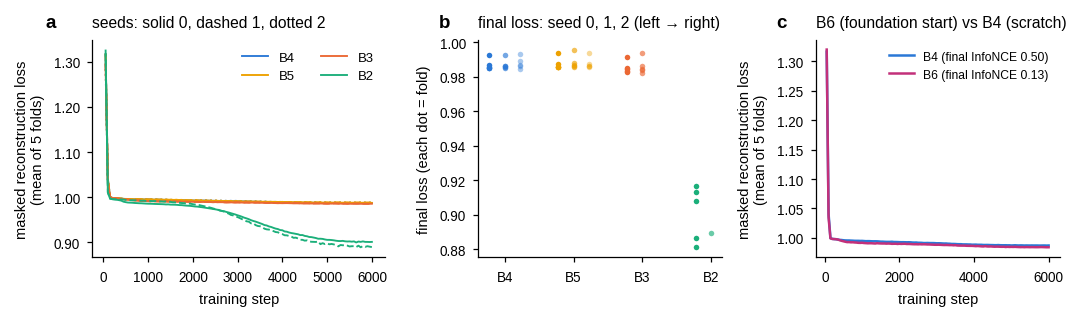

mean                     std                
seed          0       1       2       0       1       2
variant                                                
B2       0.9011  0.8896     NaN  0.0162     NaN     NaN
B3       0.9855  0.9859     NaN  0.0035  0.0044     NaN
B4       0.9871  0.9870  0.9879  0.0031  0.0030  0.0033
B5       0.9875  0.9884  0.9877  0.0034  0.0041  0.0033
B6       0.9841     NaN     NaN  0.0031     NaN     NaN

In [10]:
# ---- 8. Pretraining reproducibility across seeds + B6 vs B4 (Fig 7A-1) ------------------------------------------------------------
logs_all = []
for s in LOCO:
    for v in SEED_VARIANTS + ['B6']:
        for sd in ([0] + SEED_LIST if v != 'B6' else [0]):
            f = (os.path.join(P3_DIR, 'runs', f'{s}__{v}', 'log.csv') if (sd == 0 and v != 'B6') else os.path.join(core.run_dir(RUNS7, s, v, sd), 'log.csv'))
            if os.path.exists(f):
                d = pd.read_csv(f); d['split'], d['variant'], d['seed'] = s, v, sd; logs_all.append(d)
LOGS = pd.concat(logs_all, ignore_index=True); LOGS.to_csv(os.path.join(OUT_DIR, 'pretraining_logs_all_seeds.csv'), index=False)
FINAL = LOGS.sort_values('step').groupby(['split', 'variant', 'seed']).tail(1)
fig, axes = plt.subplots(1, 3, figsize=(W2, 55 * MM), gridspec_kw=dict(width_ratios=[1.2, 1, 1]))
ax = axes[0]
for v in SEED_VARIANTS:
    for sd, ls in zip([0] + SEED_LIST, ['-', '--', ':', '-.']):
        g = LOGS[(LOGS.variant == v) & (LOGS.seed == sd)].groupby('step').loss_rec.mean()
        if len(g): ax.plot(g.index, g.values, color=VCOL[v], ls=ls, lw=0.9, label=f'{v}' if sd == 0 else None)
ax.yaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter('%.2f'))
ax.set_xlabel('training step'); ax.set_ylabel('masked reconstruction loss\n(mean of 5 folds)'); ax.set_title('seeds: solid 0, dashed 1, dotted 2')
ax.legend(loc='upper right', ncol=2); panel(ax, 'a')
ax = axes[1]
for j, v in enumerate(SEED_VARIANTS):
    for k, sd in enumerate([0] + SEED_LIST):
        d = FINAL[(FINAL.variant == v) & (FINAL.seed == sd)].loss_rec
        ax.scatter(np.full(len(d), j + (k - 1) * 0.22), d, s=7, color=VCOL[v], alpha=[1.0, 0.65, 0.4, 0.3][k % 4], lw=0)
ax.set_xticks(range(len(SEED_VARIANTS))); ax.set_xticklabels(SEED_VARIANTS); ax.set_ylabel('final loss (each dot = fold)')
ax.set_title('final loss: seed 0, 1, 2 (left → right)'); panel(ax, 'b')
ax = axes[2]
for v in ['B4', 'B6']:
    d = LOGS[(LOGS.variant == v) & (LOGS.seed == 0)]
    g = d.groupby('step').loss_rec.mean()
    if len(g):
        nce = d.sort_values('step').groupby('split').tail(1).loss_nce.mean()
        ax.plot(g.index, g.values, color=VCOL[v], lw=1.2, label=f'{v} (final InfoNCE {nce:.2f})')
ax.yaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter('%.2f'))
ax.set_xlabel('training step'); ax.set_ylabel('masked reconstruction loss\n(mean of 5 folds)'); ax.set_title('B6 (foundation start) vs B4 (scratch)')
ax.legend(loc='upper right', fontsize=5.8); panel(ax, 'c')
fig.tight_layout(); save(fig, 'fig7A_1_pretraining_seeds')
display(FINAL.groupby(['variant', 'seed']).loss_rec.agg(['mean', 'std']).unstack('seed').round(4))

In [11]:
# ---- 9. Temporal mechanism: does the encoder use the past frames, their order, and motion? (Fig 7A-2) ---------------------------------
# frame occlusion: replace frame k of the clip by the clip's temporal mean | order: reverse / fixed shuffle | static: 8 copies of the last frame.
# Embedding change = standardised Euclidean distance (each dimension scaled by its training-movie s.d.), in units of the encoder's own
# median change over 30 s of the held-out movie, so encoders with very different embedding geometry are comparable.
# Read-outs = ridge probes (coverage, coverage change over the next 30 s) trained on the TRAINING movies' embeddings of the same encoder.
frames_meta = pd.read_csv(os.path.join(P1_DIR, 'frames_all.csv'))
tg = pd.read_csv(os.path.join(P2_DIR, 'targets_per_frame.csv')).set_index('frame_id')
lab = kept[['frame_id', 'conc', 't_rel_s']].join(tg[['coverage', 'contrast_ok']], on='frame_id')
streak = kept.frame_id.map(frames_meta.set_index('frame_id').warn_streaks).fillna(False).astype(bool).values
lab.loc[streak, 'coverage'] = np.nan
fut = []
for c, g in lab.groupby('conc'):                                   # Portion 3 definition of the dynamics label
    tt, cv = g.t_rel_s.values, g.coverage.values
    j = np.searchsorted(tt, tt + 30.0).clip(0, len(tt) - 1); ok = np.abs(tt[j] - (tt + 30.0)) <= 5.0
    fut.append(pd.Series(np.where(ok, cv[j] - cv, np.nan), index=g.index))
lab['dcov_30s'] = pd.concat(fut)
y_cov = np.where(lab.contrast_ok.astype(bool), lab.coverage, np.nan); y_dyn = lab.dcov_30s.values.astype(float)
ALPHAS = (1, 10, 100, 1000, 10000)
def ridge_readout(Z, y, trm, groups):
    """ridge read-out with alpha chosen by leave-one-concentration-out inside the training movies (Portion 3/5 rule)."""
    ok = trm & np.isfinite(y); mu, sd = Z[ok].mean(0), Z[ok].std(0) + 1e-6; A = (Z[ok] - mu) / sd; yy = y[ok]; gg = groups[ok]
    err = np.zeros(len(ALPHAS))
    for g0 in np.unique(gg):
        tr = gg != g0
        if tr.sum() < 10 or (~tr).sum() < 3: continue
        m0 = A[tr].mean(0); Ac = A[tr] - m0; ev, V = np.linalg.eigh(Ac.T @ Ac); r = V.T @ (Ac.T @ (yy[tr] - yy[tr].mean()))
        for k, al in enumerate(ALPHAS):
            err[k] += np.mean(np.abs((A[~tr] - m0) @ (V @ (r / (ev + al))) + yy[tr].mean() - yy[~tr]))
    al = ALPHAS[int(np.argmin(err))]; m0 = A.mean(0); Ac = A - m0
    w = np.linalg.solve(Ac.T @ Ac + al * np.eye(A.shape[1]), Ac.T @ (yy - yy.mean())); b = yy.mean()
    return lambda Zn: ((Zn - mu) / sd - m0) @ w + b

def saved_Z(split, v, sd):
    f = os.path.join(P3_DIR, 'embeddings', split, f'{v}.npz') if (sd == 0 and v != 'B6') else emb_path(split, v, sd)
    return np.load(f, allow_pickle=True)['Z'].astype(np.float32)

T = C.T_FRAMES; perm = np.random.default_rng(SEED).permutation(T)
while (perm == np.arange(T)).all() or (perm == np.arange(T)[::-1]).all():
    perm = np.random.default_rng(int(perm.sum())).permutation(T)
full_clip = (kept.pos.values >= (T - 1) * kept.stride.values)
TEMP_SETS = [(v, sd) for v in ['B3', 'B4', 'B5'] for sd in [0] + SEED_LIST if sd == 0 or (v, sd) in COMPLETE_SETS] + \
            ([('B6', 0)] if ('B6', 0) in COMPLETE_SETS else [])
TEMPORAL_VARIANTS = list(dict.fromkeys(v for v, _ in TEMP_SETS))
rows_t, t0 = [], time.time()
for s in LOCO:
    te_c = splits[s]['test'][0]; trm = lab.conc.isin(splits[s]['train']).values; groups = lab.conc.values
    pool = np.where((lab.conc.values == te_c) & np.isfinite(y_cov) & full_clip)[0]
    if len(pool) == 0: continue
    pick = pool[np.unique(np.linspace(0, len(pool) - 1, min(N_TEMPORAL, len(pool))).astype(int))]
    x0, = core.crop_aug([torch.as_tensor(core.causal_indices(T, pick), device=DEVICE)], C.CROP, train=False)   # (n,1,T,H,W)
    names = ['original'] + [f'occlude_{k}' for k in range(T)] + ['reversed', 'shuffled', 'static']
    def perturbed(nm):
        if nm == 'original': return x0
        if nm.startswith('occlude_'):
            xk = x0.clone(); xk[:, :, int(nm.split('_')[1])] = x0.mean(2); return xk
        if nm == 'reversed': return x0.flip(2)
        if nm == 'shuffled': return x0[:, :, torch.as_tensor(perm, device=DEVICE)]
        return x0[:, :, -1:].expand(-1, -1, T, -1, -1).contiguous()              # static: no motion
    for v, sd in TEMP_SETS:
        Zs = saved_Z(s, v, sd); f_cov = ridge_readout(Zs, y_cov, trm, groups); f_dyn = ridge_readout(Zs, y_dyn, trm, groups)
        zmu, zsd = Zs[trm].mean(0), Zs[trm].std(0) + 1e-6                 # standardised space of this encoder (training movies)
        dist = lambda a_, b_: np.linalg.norm((a_ - b_) / zsd, axis=1) / np.sqrt(a_.shape[1])
        heldZ = Zs[lab.conc.values == te_c]; tt_h = lab.t_rel_s.values[lab.conc.values == te_c]   # natural 30-s change of this encoder
        j30 = np.searchsorted(tt_h, tt_h + 30.0).clip(0, len(tt_h) - 1); okj = np.abs(tt_h[j30] - tt_h - 30.0) <= 5.0
        d30 = float(np.median(dist(heldZ[okj], heldZ[j30[okj]]))) if okj.any() else np.nan
        m = core.load_model(v, s, sd, RUNS7)
        E = np.stack([core.embed_inputs(m, perturbed(nm)).cpu().numpy() for nm in names]); del m
        e0 = E[0]; pc0 = f_cov(e0)
        for pi, nm in enumerate(names):
            e = E[pi]; cosd = dist(e, e0)
            pc, pdn = f_cov(e), f_dyn(e)
            rows_t.append(pd.DataFrame(dict(split=s, test=te_c, variant=v, seed=sd, perturbation=nm, frame=pick, d30=d30,
                                            emb_change=cosd, emb_change_rel=cosd / d30 if d30 and np.isfinite(d30) and d30 > 0 else np.nan,
                                            cov_readout=pc, d_cov_readout=np.abs(pc - pc0), dyn_readout=pdn,
                                            true_cov=y_cov[pick], true_dcov=y_dyn[pick])))
    del x0
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()
TEMP = pd.concat(rows_t, ignore_index=True)
TEMP['phase'] = np.where(TEMP.true_cov < 0.95, 'assembly', 'plateau')
TEMP.to_csv(os.path.join(OUT_DIR, 'temporal_tests_per_clip.csv'), index=False)
print(f'temporal tests: {TEMP.split.nunique()} folds x {len(TEMP_SETS)} encoder-seed sets x {TEMP.frame.nunique()} clips in {time.time() - t0:.0f}s '
      f'(shuffle used: {perm.tolist()})')
occ = TEMP[TEMP.perturbation.str.startswith('occlude_')].copy(); occ['frame_pos'] = occ.perturbation.str.split('_').str[1].astype(int)
IMP = occ.groupby(['split', 'variant', 'seed', 'frame_pos']).emb_change_rel.mean().reset_index()
ORD = TEMP[TEMP.perturbation.isin(['reversed', 'shuffled', 'static'])].groupby(['split', 'variant', 'seed', 'perturbation'])[['emb_change_rel', 'd_cov_readout']].mean().reset_index()
asm = TEMP[(TEMP.phase == 'assembly') & np.isfinite(TEMP.true_dcov)]
MOT = (asm.assign(abs_err=(asm.dyn_readout - asm.true_dcov).abs()).groupby(['split', 'variant', 'seed', 'perturbation']).abs_err.mean()
       .unstack('perturbation'))
MOT = MOT[[c for c in ['original', 'static', 'shuffled', 'reversed'] if c in MOT.columns]].reset_index()
for c in ['static', 'shuffled', 'reversed']:
    if c in MOT.columns: MOT[f'dMAE_{c}'] = MOT[c] - MOT['original']
IMP.to_csv(os.path.join(OUT_DIR, 'temporal_frame_importance.csv'), index=False); ORD.to_csv(os.path.join(OUT_DIR, 'temporal_order_sensitivity.csv'), index=False)
MOT.to_csv(os.path.join(OUT_DIR, 'temporal_motion_test.csv'), index=False)
display(ORD.groupby(['variant', 'perturbation']).emb_change_rel.mean().unstack('perturbation').round(3))
if len(MOT): display(MOT.groupby('variant')[[c for c in MOT.columns if c.startswith('dMAE_')]].mean().round(4))

temporal tests: 5 folds x 7 encoder-seed sets x 480 clips in 133s (shuffle used: [2, 4, 3, 6, 5, 0, 1, 7])


perturbation,reversed,shuffled,static
variant,,,
B3,0.679,0.697,1.063
B4,0.303,0.589,1.423
B5,0.293,0.631,1.548
B6,0.217,0.920,1.935


perturbation,dMAE_static,dMAE_shuffled,dMAE_reversed
variant,,,
B3,0.0161,-0.0017,0.0019
B4,0.0028,-0.0020,0.0010
B5,0.0034,-0.0016,0.0007
B6,-0.0009,-0.0004,0.0002


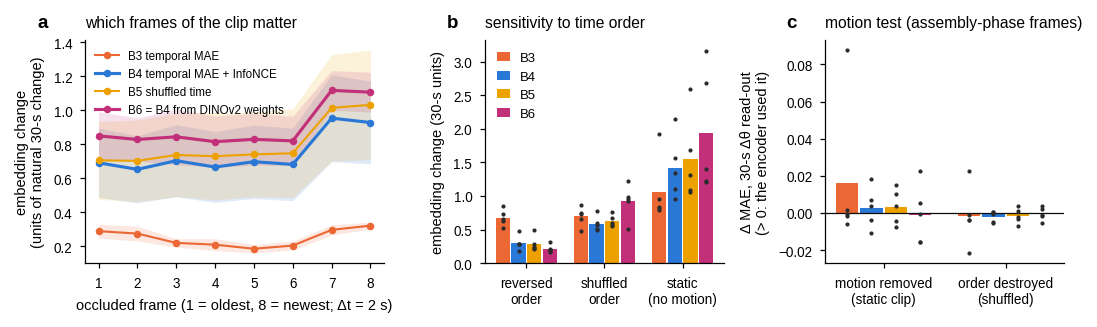

In [12]:
# ---- 10. Fig 7A-2: temporal mechanism (journal layout) ----------------------------------------------------------------------------------
TV = TEMPORAL_VARIANTS; w = 0.8 / max(1, len(TV)); off = lambda j: (j - (len(TV) - 1) / 2) * w
fig, axes = plt.subplots(1, 3, figsize=(W2, 56 * MM), gridspec_kw=dict(width_ratios=[1.25, 1, 1]))
ax = axes[0]
for v in TV:
    g = IMP[IMP.variant == v].groupby(['split', 'frame_pos']).emb_change_rel.mean().unstack('split')     # seed-mean per fold
    mu_, se = g.mean(1), g.std(1) / np.sqrt(max(1, g.shape[1]))
    ax.plot(g.index + 1, mu_, marker='o', ms=2.6, color=VCOL[v], lw=1.5 if v in ('B4', 'B6') else 1.0, label=VNAME[v])
    ax.fill_between(g.index + 1, mu_ - se, mu_ + se, color=VCOL[v], alpha=0.15, lw=0)
ax.set_xticks(range(1, T + 1)); ax.set_xlabel(f'occluded frame (1 = oldest, {T} = newest; Δt = {C.TARGET_DT:.0f} s)')
ax.set_ylabel('embedding change\n(units of natural 30-s change)'); ax.set_title('which frames of the clip matter'); ax.legend(loc='upper left', fontsize=5.6); panel(ax, 'a')
ax = axes[1]; pz = ['reversed', 'shuffled', 'static']
for j, v in enumerate(TV):
    g = ORD[ORD.variant == v].groupby(['split', 'perturbation']).emb_change_rel.mean().unstack('perturbation').reindex(columns=pz)
    ax.bar(np.arange(len(pz)) + off(j), g.mean(0), width=w * 0.92, color=VCOL[v], label=v)
    for k, p_ in enumerate(pz):
        ax.scatter(np.full(len(g), k + off(j)), g[p_], s=4, color='#2b2b2b', lw=0, zorder=3)
ax.set_xticks(range(len(pz))); ax.set_xticklabels(['reversed\norder', 'shuffled\norder', 'static\n(no motion)'])
ax.set_ylabel('embedding change (30-s units)'); ax.set_title('sensitivity to time order'); ax.legend(loc='upper left', handlelength=1); panel(ax, 'b')
ax = axes[2]
if len(MOT):
    for j, v in enumerate(TV):
        g = MOT[MOT.variant == v].groupby('split')[[c for c in ['dMAE_static', 'dMAE_shuffled'] if c in MOT.columns]].mean()
        for k, c in enumerate(g.columns):
            ax.bar(k + off(j), g[c].mean(), width=w * 0.92, color=VCOL[v])
            ax.scatter(np.full(len(g), k + off(j)), g[c], s=4, color='#2b2b2b', lw=0, zorder=3)
    ax.axhline(0, color='#0b0b0b', lw=0.6); ax.set_xticks(range(2)); ax.set_xticklabels(['motion removed\n(static clip)', 'order destroyed\n(shuffled)'])
    ax.set_ylabel('Δ MAE, 30-s Δθ read-out\n(> 0: the encoder used it)'); ax.set_title('motion test (assembly-phase frames)')
panel(ax, 'c')
fig.tight_layout(); save(fig, 'fig7A_2_temporal_mechanism')

In [13]:
# ---- 11. Checks and summary -----------------------------------------------------------------------------------------------------------
chk = [('Core module reproduces the Portion 3 encoders (B0, B2, B4)', 'PASS' if CHK.ok.all() else 'FAIL', f'min r = {CHK.correlation.min():.5f}')]
chk.append(('Training runs finished in this budget', 'PASS' if not DEFERRED else 'PARTIAL', f'{len(DONE_RUNS)}/{len(planned)}; deferred {len(DEFERRED)}'))
leak = all(set(np.load(emb_path(j['split'], j['variant'], j['seed']), allow_pickle=True)['train_concs']).isdisjoint(splits[j['split']]['test']) for j in DONE_RUNS)
chk.append(('No held-out movie in any new encoder', 'PASS' if leak else 'FAIL', f'{len(DONE_RUNS)} encoders checked'))
chk.append(('Foundation baselines embedded', 'PASS' if len(FOUND_OK) == len(FOUNDATION) else 'CHECK', ', '.join(FOUND_OK) or 'none'))
chk.append(('B6 trained on all folds', 'PASS' if ('B6', 0) in COMPLETE_SETS else ('SKIPPED' if not TRAIN_B6 else 'PARTIAL'), f'init {B6_INIT}'))
el_h = (time.time() - T_NOTEBOOK) / 3600
chk.append(('Notebook inside the time budget', 'PASS' if el_h <= TIME_BUDGET_H else 'CHECK', f'{el_h:.2f} h of {TIME_BUDGET_H:.2f} h'))
CH = pd.DataFrame(chk, columns=['check', 'status', 'detail']); display(CH); CH.to_csv(os.path.join(OUT_DIR, 'checks_portion7A.csv'), index=False)
json.dump(dict(created=datetime.now().isoformat(timespec='seconds'), device=str(DEVICE), torch=torch.__version__, timm=timm.__version__,
               portion3_quick=QUICK_P3, seeds=[0] + SEED_LIST, seed_variants=SEED_VARIANTS, loco=LOCO, workers=NW, foundation=FOUNDATION,
               foundation_ok=FOUND_OK, b6=dict(trained=('B6', 0) in COMPLETE_SETS, init=B6_INIT, enc_lr_mult=B6_ENC_LR_MULT, l2sp_anchor=B6_ANCHOR),
               complete_sets=[list(x) for x in COMPLETE_SETS], deferred=DEFERRED, time_budget_h=TIME_BUDGET_H, elapsed_h=round(el_h, 3),
               temporal_variants=TEMPORAL_VARIANTS, n_temporal=N_TEMPORAL, shuffle_perm=perm.tolist(),
               p3_config={k: v for k, v in vars(C).items() if k.isupper() and isinstance(v, (int, float, str, bool))}),
          open(os.path.join(OUT_DIR, 'run_config_portion7A.json'), 'w'), indent=1, default=str)
if QUICK_P3:
    print('\nPortion 3 ran in QUICK mode, so these numbers only prove the pipeline works.')
print(f'notebook time {el_h:.2f} h | Outputs:', sorted(os.listdir(OUT_DIR)))

,check,status,detail
0,Core module reproduces the Portion 3 encoders ...,PASS,min r = 1.00000
1,Training runs finished in this budget,PARTIAL,21/45; deferred 24
2,No held-out movie in any new encoder,PASS,21 encoders checked
3,Foundation baselines embedded,PASS,"B1-IN, B1-DINO"
4,B6 trained on all folds,PASS,init B1-DINO
5,Notebook inside the time budget,PASS,2.36 h of 2.75 h


notebook time 2.36 h | Outputs: ['arrays', 'checks_portion7A.csv', 'embeddings_foundation', 'embeddings_seeds', 'figures', 'pretraining_logs_all_seeds.csv', 'run_config_portion7A.json', 'runs_seeds', 'temporal_frame_importance.csv', 'temporal_motion_test.csv', 'temporal_order_sensitivity.csv', 'temporal_tests_per_clip.csv']


## What you have now (`portion7_outputs/`)
| File | Use |
|---|---|
| `runs_seeds/<fold>__<encoder>__s<seed>/final_encoder.pt` | fp16 encoders of B6 and the extra seeds (+ `log.csv`, `meta.json`) |
| `embeddings_seeds/`, `embeddings_foundation/` | per-frame embeddings of every new encoder, random-init B0 seeds and the B1 foundation baselines |
| `temporal_tests_per_clip.csv` + 3 summaries | frame importance, order sensitivity and motion test on held-out movies |
| `figures/fig7A_*` | seed reproducibility, B6 vs B4 training, temporal mechanism (PDF + 600-dpi PNG) |

**Next: run Portion 7B** — statistics for B6, the seeds and the foundation baselines, forecasting regimes, Figures 6–8 and tables.
**If the session ends early:** re-run all cells; finished runs are skipped and the queue continues (runs interrupted mid-way restart
from their last local checkpoint if the same Colab machine is still attached, otherwise from the beginning).